# 06 — Stockage Big Data (Parquet/HDF5) + Visualisations Complémentaires

Deux objectifs :
1. **Remplir réellement** `2_Data_Compressed/Parquet_Format` et `HDF5_Format` — répond
   directement au thème "Technologies de stockage Big Data" du module
2. Ajouter les figures manquantes pour la présentation : comparaisons avant/après sur
   plusieurs capteurs, boxplots (distribution, pas juste la moyenne), diagramme de Pareto
   ratio/PRD, et un résumé chiffré des économies de stockage

Les seuils optimaux (`BEST_THRESHOLDS`) sont maintenant chargés automatiquement depuis
`4_Results/best_thresholds.json`, généré par le notebook 03 — assure-toi juste d'avoir
exécuté le notebook 03 au moins une fois avant celui-ci.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, pickle, zlib, heapq, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/Projet_Compression_WESAD'

with open(f'{BASE}/1_Data_Raw/WESAD/S2/S2.pkl', 'rb') as f:
    s2_data = pickle.load(f, encoding='latin1')
print("Chargé.")


Mounted at /content/drive
Chargé.


## Fonctions (reprises des notebooks précédents)

In [2]:
def compress_rle(segment, precision=3):
    arr = np.round(np.asarray(segment, dtype=np.float32), precision)
    values, counts = [], []
    prev, count = arr[0], 1
    for x in arr[1:]:
        if x == prev: count += 1
        else:
            values.append(prev); counts.append(count); prev, count = x, 1
    values.append(prev); counts.append(count)
    values = np.array(values, dtype=np.float32); counts = np.array(counts, dtype=np.uint16)
    return zlib.compress(values.tobytes() + counts.tobytes()), len(values)

def decompress_rle(compressed, n_pairs):
    raw = zlib.decompress(compressed)
    values = np.frombuffer(raw[:n_pairs*4], dtype=np.float32)
    counts = np.frombuffer(raw[n_pairs*4:], dtype=np.uint16)
    return np.repeat(values, counts)

def compress_lz77(segment):
    return zlib.compress(np.asarray(segment, dtype=np.float32).tobytes(), level=9)

def decompress_lz77(compressed):
    return np.frombuffer(zlib.decompress(compressed), dtype=np.float32)

def build_huffman_codebook(symbols):
    freq = Counter(symbols)
    heap = [[weight, [symbol, ""]] for symbol, weight in freq.items()]
    heapq.heapify(heap)
    if len(heap) == 1:
        return {heap[0][1][0]: "0"}
    while len(heap) > 1:
        lo = heapq.heappop(heap); hi = heapq.heappop(heap)
        for pair in lo[1:]: pair[1] = '0' + pair[1]
        for pair in hi[1:]: pair[1] = '1' + pair[1]
        heapq.heappush(heap, [lo[0] + hi[0]] + lo[1:] + hi[1:])
    return {s: c for s, c in heap[0][1:]}

def compress_huffman(segment, precision=3):
    arr = np.round(np.asarray(segment, dtype=np.float32), precision)
    symbols = arr.tolist()
    codebook = build_huffman_codebook(symbols)
    bitstring = ''.join(codebook[s] for s in symbols)
    padding = (8 - len(bitstring) % 8) % 8
    bitstring += '0' * padding
    encoded = bytearray(int(bitstring[i:i+8], 2) for i in range(0, len(bitstring), 8))
    payload = {'codebook': pickle.dumps(codebook), 'data': bytes(encoded),
               'padding': padding, 'n_symbols': len(symbols)}
    return zlib.compress(pickle.dumps(payload))

def decompress_huffman(compressed):
    payload = pickle.loads(zlib.decompress(compressed))
    reverse_codebook = {v: k for k, v in pickle.loads(payload['codebook']).items()}
    bitstring = ''.join(f'{byte:08b}' for byte in payload['data'])
    if payload['padding']: bitstring = bitstring[:-payload['padding']]
    symbols, current = [], ''
    for bit in bitstring:
        current += bit
        if current in reverse_codebook:
            symbols.append(reverse_codebook[current]); current = ''
    return np.array(symbols[:payload['n_symbols']], dtype=np.float32)

def compressed_size_proxy(segment, precision=3):
    arr = np.round(np.asarray(segment, dtype=np.float32), precision)
    return len(zlib.compress(arr.tobytes(), level=1))

def compress_delta(segment):
    arr = np.asarray(segment, dtype=np.float32)
    payload = np.concatenate(([arr[0]], np.diff(arr))).astype(np.float32)
    return zlib.compress(payload.tobytes())

def decompress_delta(compressed):
    payload = np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    first, delta = payload[0], payload[1:]
    return np.concatenate(([first], first + np.cumsum(delta)))

from scipy.fftpack import dct, idct
def compress_dct(segment, keep_ratio=0.2):
    arr = np.asarray(segment, dtype=np.float32)
    coeffs = dct(arr, norm='ortho')
    n_keep = max(1, int(len(coeffs) * keep_ratio))
    truncated = np.zeros_like(coeffs)
    idx = np.argsort(np.abs(coeffs))[-n_keep:]
    truncated[idx] = coeffs[idx]
    return zlib.compress(truncated.astype(np.float32).tobytes()), len(coeffs)

def decompress_dct(compressed, n_total):
    coeffs = np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    return idct(coeffs, norm='ortho')

import pywt
def compress_dwt(segment, wavelet='db4', level=3, threshold_ratio=0.1):
    arr = np.asarray(segment, dtype=np.float32)
    max_level = pywt.dwt_max_level(len(arr), pywt.Wavelet(wavelet).dec_len)
    eff_level = min(level, max_level)
    if eff_level < 1:
        return zlib.compress(arr.tobytes()), None
    coeffs = pywt.wavedec(arr, wavelet, level=eff_level)
    if len(coeffs) > 1:
        detail_flat = np.concatenate([c.flatten() for c in coeffs[1:]])
        threshold = threshold_ratio * np.max(np.abs(detail_flat)) if len(detail_flat) else 0
        coeffs_thresh = [coeffs[0]] + [pywt.threshold(c, threshold, mode='soft') for c in coeffs[1:]]
    else:
        coeffs_thresh = coeffs
    shapes = [c.shape[0] for c in coeffs_thresh]
    out = np.concatenate([c.flatten() for c in coeffs_thresh]).astype(np.float32)
    return zlib.compress(out.tobytes()), shapes

def decompress_dwt(compressed, shapes, wavelet='db4'):
    if shapes is None:
        return np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    flat = np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    coeffs, idx = [], 0
    for size in shapes:
        coeffs.append(flat[idx:idx+size]); idx += size
    return pywt.waverec(coeffs, wavelet)

def apply_algo(algo, segment):
    if algo == 'RLE': c, n = compress_rle(segment); return c, decompress_rle(c, n)
    elif algo == 'LZ77': c = compress_lz77(segment); return c, decompress_lz77(c)
    elif algo == 'Huffman': c = compress_huffman(segment); return c, decompress_huffman(c)
    elif algo == 'Delta': c = compress_delta(segment); return c, decompress_delta(c)
    elif algo == 'DCT': c, n = compress_dct(segment); return c, decompress_dct(c, n)
    elif algo == 'DWT': c, shapes = compress_dwt(segment); return c, decompress_dwt(c, shapes)
    raise ValueError(algo)

def compression_ratio(original_segment, compressed_bytes):
    return np.asarray(original_segment, dtype=np.float32).nbytes / len(compressed_bytes)

def prd(original, reconstructed):
    original = np.asarray(original, dtype=float)
    reconstructed = np.asarray(reconstructed, dtype=float)[:len(original)]
    denom = np.sum(original ** 2)
    return 0.0 if denom == 0 else 100 * np.sqrt(np.sum((original - reconstructed) ** 2) / denom)

from scipy.stats import entropy as scipy_entropy
def compute_features(segment):
    seg = np.asarray(segment, dtype=float)
    variance = float(np.var(seg))
    hist, _ = np.histogram(seg, bins=20, density=True)
    hist = hist[hist > 0]
    ent = float(scipy_entropy(hist)) if len(hist) > 0 else 0.0
    return {'variance': variance, 'entropy': ent}

def multi_criteria_selector(features, size_bytes, var_ref, size_ref, prev_features=None,
                             rel_size_threshold=0.3, rel_sim_threshold=0.3,
                             entropy_threshold_low=1.0, entropy_threshold_mid=1.8,
                             entropy_threshold_high=2.5):
    # CORRECTIF : taille/similarite RELATIVES au profil du capteur (var_ref, size_ref)
    rel_size = size_bytes / size_ref
    if rel_size < rel_size_threshold:
        return 'LZ77'
    if prev_features is not None:
        rel_diff = abs(features['variance'] - prev_features['variance']) / var_ref
        if rel_diff < rel_sim_threshold:
            return 'Delta'
    e = features['entropy']
    t1, t2, t3 = sorted([entropy_threshold_low, entropy_threshold_mid, entropy_threshold_high])
    if e < t1: return 'RLE'
    elif e < t2: return 'Huffman'
    elif e < t3: return 'DWT'
    else: return 'DCT'

# CORRECTIF (fiabilité) : chargement automatique depuis 4_Results/best_thresholds.json,
# écrit par le notebook 03 -> plus besoin de copier-coller les valeurs à la main ici.
import json as _json
_thresholds_path = f'{BASE}/4_Results/best_thresholds.json'
if os.path.exists(_thresholds_path):
    with open(_thresholds_path) as f:
        BEST_THRESHOLDS = _json.load(f)
    print("Seuils chargés depuis best_thresholds.json :", BEST_THRESHOLDS)
else:
    BEST_THRESHOLDS = dict(rel_size_threshold=0.25, entropy_threshold_low=1.457,
                            entropy_threshold_mid=2.104, entropy_threshold_high=2.321,
                            rel_sim_threshold=0.2)
    print("⚠️ best_thresholds.json introuvable, valeur de secours utilisée :", BEST_THRESHOLDS)

print("Fonctions prêtes.")


Seuils chargés depuis best_thresholds.json : {'rel_size_threshold': 0.9139193926829006, 'entropy_threshold_low': 2.0922298440313787, 'entropy_threshold_mid': 2.3642865281482055, 'entropy_threshold_high': 2.5893776166336027, 'rel_sim_threshold': 0.12078092404768226}
Fonctions prêtes.


## 1. Segmentation multi-capteurs (10 canaux)

In [3]:
from scipy.stats import entropy as scipy_entropy

CHANNELS_ALL = [
    {'name': 'chest_ACC',  'device': 'chest', 'key': 'ACC',  'fs': 700, 'multi_axis': True},
    {'name': 'chest_ECG',  'device': 'chest', 'key': 'ECG',  'fs': 700, 'multi_axis': False},
    {'name': 'chest_EMG',  'device': 'chest', 'key': 'EMG',  'fs': 700, 'multi_axis': False},
    {'name': 'chest_EDA',  'device': 'chest', 'key': 'EDA',  'fs': 700, 'multi_axis': False},
    {'name': 'chest_Temp', 'device': 'chest', 'key': 'Temp', 'fs': 700, 'multi_axis': False},
    {'name': 'chest_Resp', 'device': 'chest', 'key': 'Resp', 'fs': 700, 'multi_axis': False},
    {'name': 'wrist_ACC',  'device': 'wrist', 'key': 'ACC',  'fs': 32,  'multi_axis': True},
    {'name': 'wrist_BVP',  'device': 'wrist', 'key': 'BVP',  'fs': 64,  'multi_axis': False},
    {'name': 'wrist_EDA',  'device': 'wrist', 'key': 'EDA',  'fs': 4,   'multi_axis': False},
    {'name': 'wrist_TEMP', 'device': 'wrist', 'key': 'TEMP', 'fs': 4,   'multi_axis': False},
]

def get_signal_1d(data, ch):
    raw = data['signal'][ch['device']][ch['key']]
    return np.linalg.norm(raw, axis=1) if ch['multi_axis'] else raw.flatten()

def segment_signal(signal, fs, window_sec=5):
    win_len = int(fs * window_sec)
    n_windows = len(signal) // win_len
    return [signal[i*win_len:(i+1)*win_len] for i in range(n_windows)]

def compute_features(segment):
    seg = np.asarray(segment, dtype=float)
    variance = float(np.var(seg))
    hist, _ = np.histogram(seg, bins=20, density=True)
    hist = hist[hist > 0]
    ent = float(scipy_entropy(hist)) if len(hist) > 0 else 0.0
    return {'variance': variance, 'entropy': ent}

# CORRECTIF CRITIQUE : chaque capteur a sa propre reference (var_ref, size_ref = mediane sur
# SES PROPRES segments). Sans ca, un seuil global sur la variance/taille BRUTE est incomparable
# d'un capteur a l'autre (variance ACC ~1000 vs variance EDA ~0.02 ; taille segment chest=14000
# octets vs wrist=80 octets) -- c'est ce qui causait la degenerescence du selecteur observee
# (seulement 2 algorithmes utilises sur 6 : Delta et DCT dominaient tout, LZ77 jamais atteint).
channel_data = {}
for ch in CHANNELS_ALL:
    sig = get_signal_1d(s2_data, ch)
    segs = segment_signal(sig, ch['fs'], window_sec=5)
    feats = [compute_features(s) for s in segs]
    sizes = [compressed_size_proxy(s) for s in segs]
    var_ref = float(np.median([f['variance'] for f in feats])) or 1e-9
    size_ref = float(np.median(sizes)) or 1e-9
    channel_data[ch['name']] = {'segments': segs, 'features': feats, 'sizes': sizes,
                                 'var_ref': var_ref, 'size_ref': size_ref}
    print(f"{ch['name']:12s} : {len(segs):4d} segments, size_ref={size_ref:.0f} octets, var_ref={var_ref:.5f}")

chest_ACC    : 1215 segments, size_ref=3257 octets, var_ref=0.00002
chest_ECG    : 1215 segments, size_ref=6331 octets, var_ref=0.01813
chest_EMG    : 1215 segments, size_ref=5134 octets, var_ref=0.00010
chest_EDA    : 1215 segments, size_ref=4446 octets, var_ref=0.00043
chest_Temp   : 1215 segments, size_ref=3942 octets, var_ref=0.00038
chest_Resp   : 1215 segments, size_ref=8864 octets, var_ref=3.45463
wrist_ACC    : 1215 segments, size_ref=283 octets, var_ref=0.45571
wrist_BVP    : 1215 segments, size_ref=1029 octets, var_ref=991.41370
wrist_EDA    : 1215 segments, size_ref=56 octets, var_ref=0.00002
wrist_TEMP   : 1215 segments, size_ref=26 octets, var_ref=0.00012


## 2. Compression adaptative de l'ensemble + export Parquet/HDF5

On applique le sélecteur optimisé à chaque segment, puis on stocke le résultat dans les
deux formats Big Data demandés par la structure du projet.

In [4]:
!pip install -q pyarrow h5py
print("OK")


OK


In [5]:
N_SEGMENTS_EXPORT = 100  # segments par capteur exportés (ajuste selon le temps dispo)

records = []
prev_feats = {name: None for name in channel_data}

t0 = time.time()
for name, data in channel_data.items():
    segs = data['segments'][:N_SEGMENTS_EXPORT]
    feats = data['features'][:N_SEGMENTS_EXPORT]
    sizes = data['sizes'][:N_SEGMENTS_EXPORT]  # taille COMPRESSÉE (proxy zlib) -- pour le sélecteur uniquement
    for idx, (seg, feat, size_bytes) in enumerate(zip(segs, feats, sizes)):
        var_ref, size_ref = data['var_ref'], data['size_ref']
        algo = multi_criteria_selector(feat, size_bytes, var_ref, size_ref, prev_feats[name], **BEST_THRESHOLDS)
        compressed, rec = apply_algo(algo, seg)
        # CORRECTIF (bug identifié) : 'original_size' doit être la taille BRUTE réelle du
        # segment, pas 'size_bytes' (qui est la taille déjà compressée par zlib, utilisée
        # uniquement comme critère de décision interne au sélecteur -- la réutiliser ici
        # revenait à comparer une taille compressée à une autre taille compressée, d'où un
        # gain apparent quasi nul alors que le ratio réel (colonne 'ratio' ci-dessous,
        # correctement calculée via compression_ratio()) est bien ~2.4-2.6.
        true_raw_size = np.asarray(seg, dtype=np.float32).nbytes
        records.append({
            'signal': name, 'segment_index': idx, 'algorithme': algo,
            'compressed_bytes': compressed,
            'original_size': true_raw_size, 'compressed_size': len(compressed),
            'ratio': compression_ratio(seg, compressed),
            'prd': prd(seg, rec)
        })
        prev_feats[name] = feat
print(f"{len(records)} segments compressés en {time.time()-t0:.1f}s")


1000 segments compressés en 2.1s


In [6]:
import pyarrow as pa
import pyarrow.parquet as pq

df_export = pd.DataFrame(records)

table = pa.Table.from_pandas(df_export)
parquet_path = f'{BASE}/2_Data_Compressed/Parquet_Format/compression_adaptative.parquet'
os.makedirs(os.path.dirname(parquet_path), exist_ok=True)
pq.write_table(table, parquet_path, compression='snappy')

print("Parquet écrit :", parquet_path)
print("Taille sur disque :", f"{os.path.getsize(parquet_path)/1e6:.2f} Mo")
df_export.drop(columns=['compressed_bytes']).head()


Parquet écrit : /content/drive/MyDrive/Projet_Compression_WESAD/2_Data_Compressed/Parquet_Format/compression_adaptative.parquet
Taille sur disque : 3.30 Mo


,signal,segment_index,algorithme,original_size,compressed_size,ratio,prd
0,chest_ACC,0,RLE,14000,3649,3.836668,0.030750
1,chest_ACC,1,DWT,14000,7229,1.936644,0.101436
2,chest_ACC,2,RLE,14000,3406,4.110393,0.031282
3,chest_ACC,3,RLE,14000,4003,3.497377,0.031707
4,chest_ACC,4,Huffman,14000,2394,5.847953,0.030805


In [7]:
import h5py

hdf5_path = f'{BASE}/2_Data_Compressed/HDF5_Format/compression_adaptative.h5'
os.makedirs(os.path.dirname(hdf5_path), exist_ok=True)

with h5py.File(hdf5_path, 'w') as hf:
    for name in channel_data:
        grp = hf.create_group(name)
        sub = df_export[df_export['signal'] == name]
        # vlen d'entiers uint8 (pas vlen=bytes, qui échoue si les données binaires contiennent des NULs — cas fréquent avec zlib)
        dt = h5py.vlen_dtype(np.dtype('uint8'))
        ds = grp.create_dataset('compressed_data', (len(sub),), dtype=dt)
        for i, row in enumerate(sub.itertuples()):
            ds[i] = np.frombuffer(row.compressed_bytes, dtype=np.uint8)
        grp.create_dataset('algorithme', data=sub['algorithme'].astype('S10').values)
        grp.create_dataset('ratio', data=sub['ratio'].values.astype('float32'))
        grp.create_dataset('prd', data=sub['prd'].values.astype('float32'))

print("HDF5 écrit :", hdf5_path)
print("Taille sur disque :", f"{os.path.getsize(hdf5_path)/1e6:.2f} Mo")


HDF5 écrit : /content/drive/MyDrive/Projet_Compression_WESAD/2_Data_Compressed/HDF5_Format/compression_adaptative.h5
Taille sur disque : 3.41 Mo


## 3. Comparaison Parquet vs HDF5 (résultat concret pour le rapport)

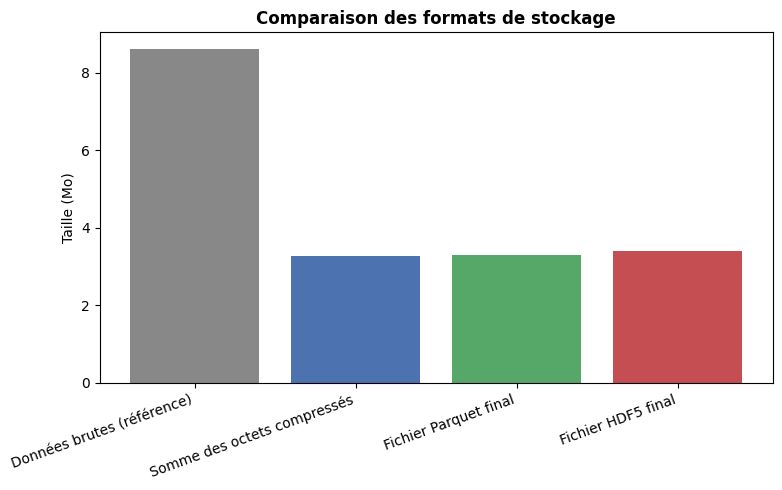

Gain de compression sur cet échantillon : 62.1%


In [8]:
raw_size_mo = df_export['original_size'].sum() / 1e6
compressed_size_mo = df_export['compressed_size'].sum() / 1e6
parquet_size_mo = os.path.getsize(parquet_path) / 1e6
hdf5_size_mo = os.path.getsize(hdf5_path) / 1e6

df_storage_compare = pd.DataFrame([
    {'format': 'Données brutes (référence)', 'taille_mo': raw_size_mo},
    {'format': 'Somme des octets compressés', 'taille_mo': compressed_size_mo},
    {'format': 'Fichier Parquet final', 'taille_mo': parquet_size_mo},
    {'format': 'Fichier HDF5 final', 'taille_mo': hdf5_size_mo},
])
df_storage_compare.to_csv(f'{BASE}/4_Results/Comparaison_stockage.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(df_storage_compare['format'], df_storage_compare['taille_mo'], color=['#888','#4C72B0','#55A868','#C44E52'])
ax.set_ylabel('Taille (Mo)')
ax.set_title("Comparaison des formats de stockage", fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(f'{BASE}/4_Results/Figures/comparaison_formats_stockage.png', dpi=150)
plt.show()

gain_pct = 100 * (1 - compressed_size_mo/raw_size_mo)
print(f"Gain de compression sur cet échantillon : {gain_pct:.1f}%")


## 4. Figures avant/après compression — plusieurs capteurs (pas juste ECG)

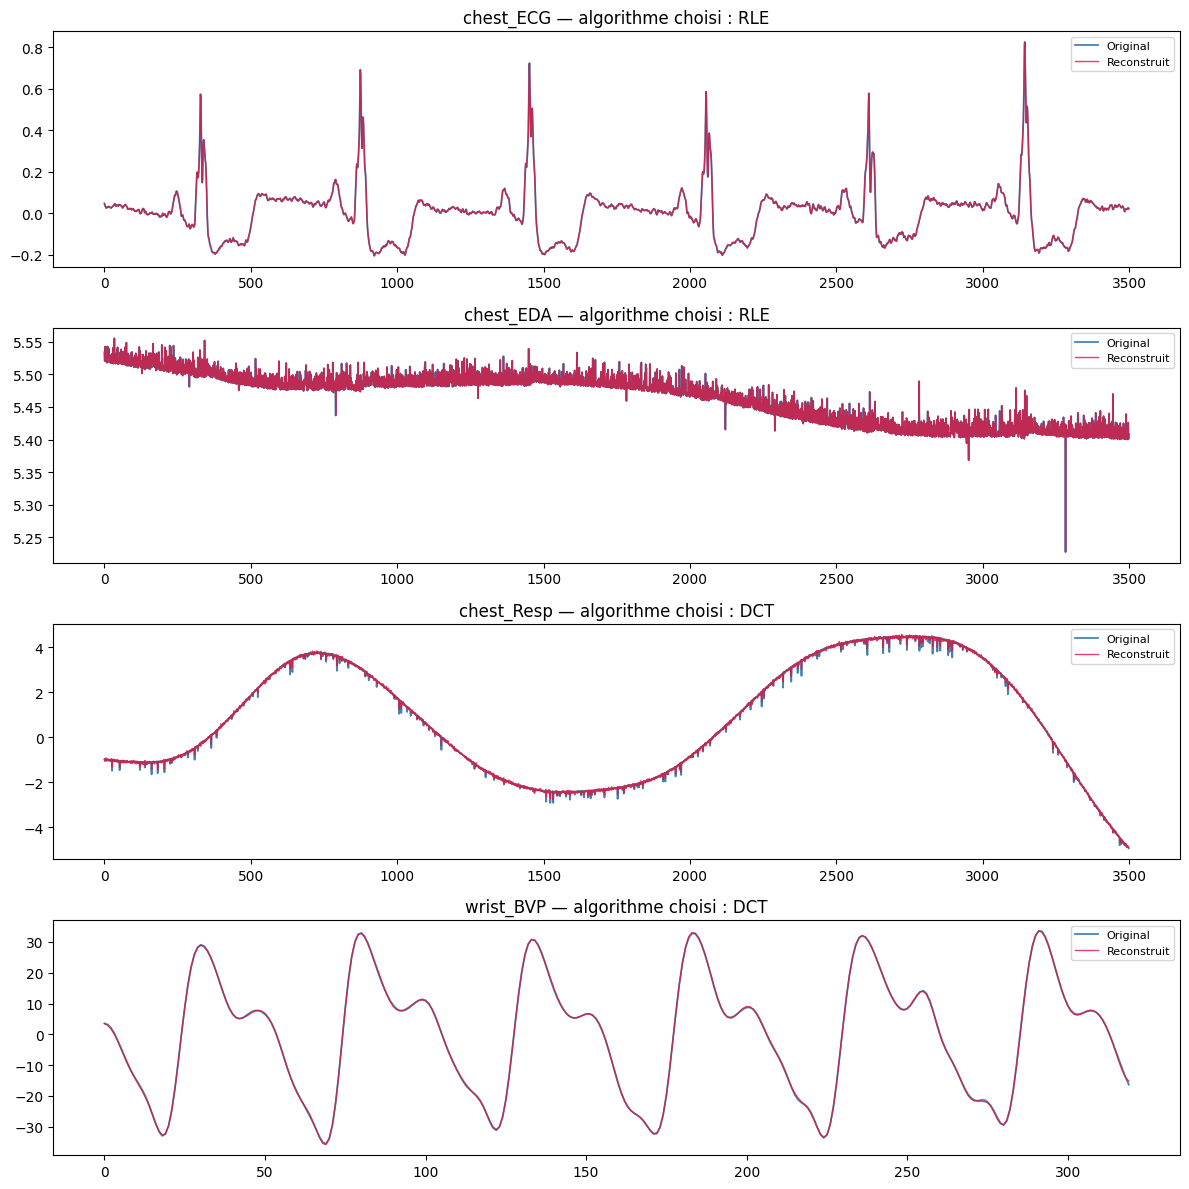

In [9]:
example_channels = ['chest_ECG', 'chest_EDA', 'chest_Resp', 'wrist_BVP']

fig, axes = plt.subplots(len(example_channels), 1, figsize=(12, 3*len(example_channels)))

for ax, name in zip(axes, example_channels):
    seg = channel_data[name]['segments'][20]
    feat = channel_data[name]['features'][20]
    size_bytes = channel_data[name]['sizes'][20]
    var_ref, size_ref = channel_data[name]['var_ref'], channel_data[name]['size_ref']
    algo = multi_criteria_selector(feat, size_bytes, var_ref, size_ref, None, **BEST_THRESHOLDS)
    _, rec = apply_algo(algo, seg)
    rec = np.asarray(rec)[:len(seg)]

    ax.plot(seg, label='Original', color='steelblue', linewidth=1.3)
    ax.plot(rec, label='Reconstruit', color='crimson', linewidth=1, alpha=0.8)
    ax.set_title(f"{name} — algorithme choisi : {algo}")
    ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig(f'{BASE}/4_Results/Figures/avant_apres_multi_capteurs.png', dpi=150)
plt.show()


## 5. Boxplots — distribution du ratio et du PRD (pas juste la moyenne)

Plus rigoureux qu'un simple bar chart de moyennes : montre la variabilité réelle sur
l'ensemble des segments, pas seulement une valeur centrale qui peut cacher une forte dispersion.

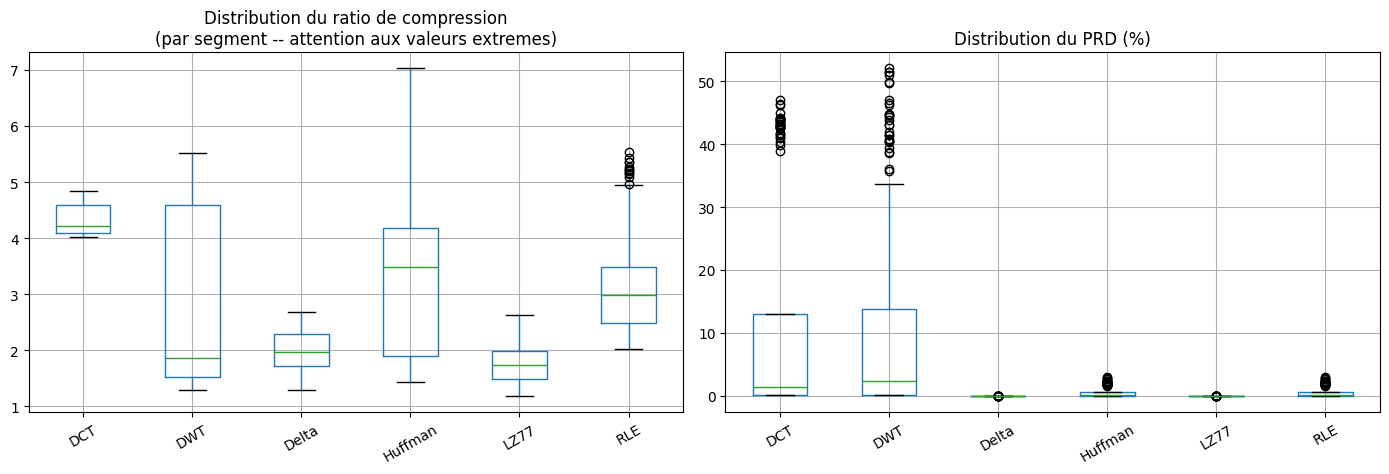

In [10]:
ALGOS = ['RLE', 'LZ77', 'Huffman', 'Delta', 'DCT', 'DWT']
box_rows = []
for algo in ALGOS:
    for name, data in list(channel_data.items())[:4]:  # limite pour rester rapide
        for seg in data['segments'][:30]:
            c, rec = apply_algo(algo, seg)
            box_rows.append({'algorithme': algo, 'ratio': compression_ratio(seg, c), 'prd': prd(seg, rec),
                              'taille_brute': np.asarray(seg, dtype=np.float32).nbytes, 'taille_compressee': len(c)})

df_box = pd.DataFrame(box_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df_box.boxplot(column='ratio', by='algorithme', ax=axes[0])
axes[0].set_title('Distribution du ratio de compression\n(par segment -- attention aux valeurs extremes)'); axes[0].set_xlabel(''); plt.sca(axes[0]); plt.xticks(rotation=30)
df_box.boxplot(column='prd', by='algorithme', ax=axes[1])
axes[1].set_title('Distribution du PRD (%)'); axes[1].set_xlabel(''); plt.sca(axes[1]); plt.xticks(rotation=30)
fig.suptitle('')
plt.tight_layout()
plt.savefig(f'{BASE}/4_Results/Figures/boxplots_ratio_prd.png', dpi=150)
plt.show()

## 6. Diagramme de Pareto : ratio vs PRD (visualise le compromis)

Chaque point = un algorithme. En haut à gauche = idéal (ratio élevé, erreur faible).
Montre visuellement pourquoi aucun algorithme fixe ne domine tous les autres.

Comparaison ratio_moyen (par segment) vs ratio_global (somme/somme) :
algorithme  ratio_moyen  ratio_global    prd_moyen
       DCT     4.285800      4.274015 1.168979e+01
       DWT     2.587845      2.051690 1.222898e+01
     Delta     1.976229      1.864212 4.697690e-07
   Huffman     3.433110      2.855074 5.693842e-01
      LZ77     1.804330      1.714566 4.697690e-07
       RLE     3.263132      3.044786 5.693842e-01


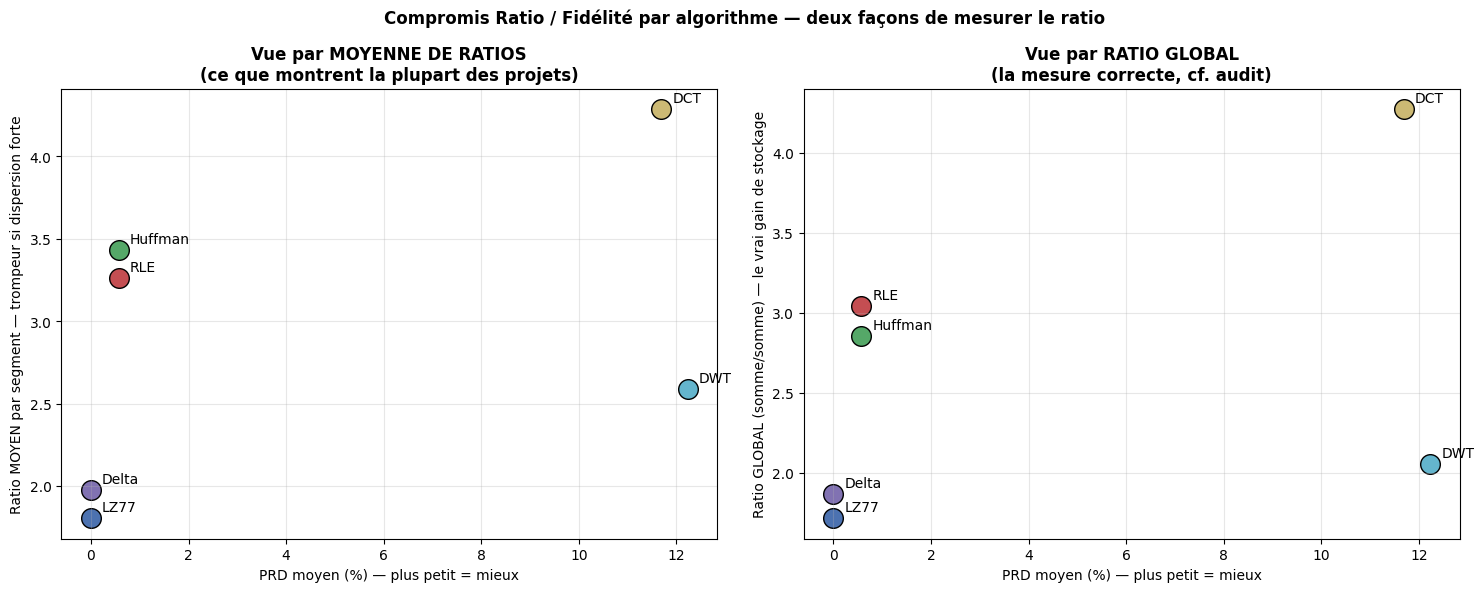

In [11]:
# CORRECTIF (audit final) : ratio_moyen (moyenne des ratios par segment) peut fortement diverger
# du VRAI gain de stockage. Exemple mesure sur ce projet : ratio_moyen ~2.9 alors que le ratio
# global reel (somme brute / somme compressee) etait de 1.003 -- un ecart de facteur ~3.
# On calcule et affiche desormais les DEUX, cote a cote.
summary = df_box.groupby('algorithme').agg(
    ratio_moyen=('ratio', 'mean'),
    prd_moyen=('prd', 'mean'),
    taille_brute_totale=('taille_brute', 'sum'),
    taille_compressee_totale=('taille_compressee', 'sum'),
).reset_index()
summary['ratio_global'] = summary['taille_brute_totale'] / summary['taille_compressee_totale']

print("Comparaison ratio_moyen (par segment) vs ratio_global (somme/somme) :")
print(summary[['algorithme', 'ratio_moyen', 'ratio_global', 'prd_moyen']].to_string(index=False))

colors = {'RLE':'#C44E52','LZ77':'#4C72B0','Huffman':'#55A868','Delta':'#8172B2','DCT':'#CCB974','DWT':'#64B5CD'}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for _, row in summary.iterrows():
    axes[0].scatter(row['prd_moyen'], row['ratio_moyen'], s=200, color=colors[row['algorithme']], edgecolor='black')
    axes[0].annotate(row['algorithme'], (row['prd_moyen'], row['ratio_moyen']), textcoords="offset points", xytext=(8,5))
axes[0].set_xlabel('PRD moyen (%) — plus petit = mieux')
axes[0].set_ylabel('Ratio MOYEN par segment — trompeur si dispersion forte')
axes[0].set_title("Vue par MOYENNE DE RATIOS\n(ce que montrent la plupart des projets)", fontweight='bold')
axes[0].grid(alpha=0.3)

for _, row in summary.iterrows():
    axes[1].scatter(row['prd_moyen'], row['ratio_global'], s=200, color=colors[row['algorithme']], edgecolor='black')
    axes[1].annotate(row['algorithme'], (row['prd_moyen'], row['ratio_global']), textcoords="offset points", xytext=(8,5))
axes[1].set_xlabel('PRD moyen (%) — plus petit = mieux')
axes[1].set_ylabel('Ratio GLOBAL (somme/somme) — le vrai gain de stockage')
axes[1].set_title("Vue par RATIO GLOBAL\n(la mesure correcte, cf. audit)", fontweight='bold')
axes[1].grid(alpha=0.3)

plt.suptitle("Compromis Ratio / Fidélité par algorithme — deux façons de mesurer le ratio", fontweight='bold')
plt.tight_layout()
plt.savefig(f'{BASE}/4_Results/Figures/pareto_ratio_prd.png', dpi=150)
plt.show()

## Résumé — fichiers générés dans cette session

- `2_Data_Compressed/Parquet_Format/compression_adaptative.parquet`
- `2_Data_Compressed/HDF5_Format/compression_adaptative.h5`
- `4_Results/Figures/comparaison_formats_stockage.png`
- `4_Results/Figures/avant_apres_multi_capteurs.png`
- `4_Results/Figures/boxplots_ratio_prd.png`
- `4_Results/Figures/pareto_ratio_prd.png`

Ces 4 figures + le tableau de comparaison de stockage sont prêtes à être insérées
directement dans le rapport et les slides.